### Import bibliotek

`moje_kolory` dla lepszej wizualizacji wyników

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from matplotlib.colors import ListedColormap
from lab3.wzorce_cyfr import (cyfra_0, cyfra_1, cyfra_2, cyfra_3, cyfra_4,
                              cyfra_5, cyfra_6, cyfra_7, cyfra_8, cyfra_9)

moje_kolory = ListedColormap(['darkblue', 'yellow'])

### Przygotowanie danych

In [2]:
wzorce = [cyfra_0, cyfra_1, cyfra_2, cyfra_3, cyfra_4,
          cyfra_5, cyfra_6, cyfra_7, cyfra_8, cyfra_9]

### Metoda na dodanie szumu

In [3]:
def dodajSzum(obraz, poziom_szumu):
    zaszumiony_obraz = obraz.copy().flatten()
    liczba_pikseli = len(zaszumiony_obraz)

    ile_zmienic = int(liczba_pikseli * (poziom_szumu / 100.0))
    indeksy_do_zepsucia = random.sample(range(liczba_pikseli), ile_zmienic)

    for i in indeksy_do_zepsucia:
        zaszumiony_obraz[i] *= -1

    return zaszumiony_obraz.reshape((8, 8))

### Metoda do wyświetlania wzorców przed i po zaszumieniu

In [5]:
def wyswietlPrzedIPoZaszumieniu(wzorzec, poziomZaszumienia):
    fig, osie = plt.subplots(1, 2)
    osie[0].imshow(wzorzec, cmap=moje_kolory)
    osie[0].set_title("Oryginał")
    osie[1].imshow(dodajSzum(wzorzec, poziomZaszumienia), cmap=moje_kolory)
    osie[1].set_title(f"{poziomZaszumienia}% zaszumienia")
    for os in osie:
        os.axis('off')
    plt.show()

### Obliczanie pola lokalnego neuronu i jego aktualizacja

Zastosowanie tolerancji 1e-7 ze względu na zaokrąglenia ułamków z pseudoinwersji

In [6]:
def oblicz_pole_lokalne(i, wagi, stan_sieci):
    h_i = np.dot(wagi[i], stan_sieci)
    return h_i

def aktualizuj_neuron(i, wagi, stan_sieci):
    h_i = oblicz_pole_lokalne(i, wagi, stan_sieci)
    if h_i > 1e-7:
        stan_sieci[i] = 1
    elif h_i < -1e-7:
        stan_sieci[i] = -1
    return stan_sieci

### Metoda do odtwarzania obrazów

In [7]:
def odtworz_obraz(zaszumiony_obraz, wagi, maks_iteracji):
    stan_sieci = zaszumiony_obraz.copy().flatten()
    liczba_neuronow = len(stan_sieci)
    for i in range(maks_iteracji):
        liczba_zmian = 0
        for i in range(liczba_neuronow):
            stary_stan = stan_sieci[i]
            stan_sieci = aktualizuj_neuron(i, wagi, stan_sieci)
            if stary_stan != stan_sieci[i]:
                liczba_zmian += 1
        if liczba_zmian == 0:
            break
    return stan_sieci.reshape((8, 8))

### Hopfield

In [8]:
liczba_neuronow = 64
wagi = np.zeros((liczba_neuronow, liczba_neuronow))

for wzorzec in wzorce[:3]:
    wzorzec_na_plasko = wzorzec.flatten()
    for i in range(liczba_neuronow):
        for j in range(liczba_neuronow):
            if i != j:
                wagi[i, j] += wzorzec_na_plasko[i] * wzorzec_na_plasko[j]

wagi = wagi / liczba_neuronow

### Sprawdzenie wymagane w materiałach do zajęć

In [9]:
print("\n===Testy macierzy wag===\n")
print("\nCzy macierz wag jest symetryczna?")
czy_symetryczna = np.allclose(wagi, wagi.T)
print(czy_symetryczna)
print("\nCzy na przekatnej są zera?")
przekatna = np.diag(wagi)
czy_zera_na_przekatnej = np.all(przekatna == 0)
print(czy_zera_na_przekatnej)


===Testy macierzy wag===


Czy macierz wag jest symetryczna?
True

Czy na przekatnej są zera?
True


### Wizualizacja działania sieci Hopfielda

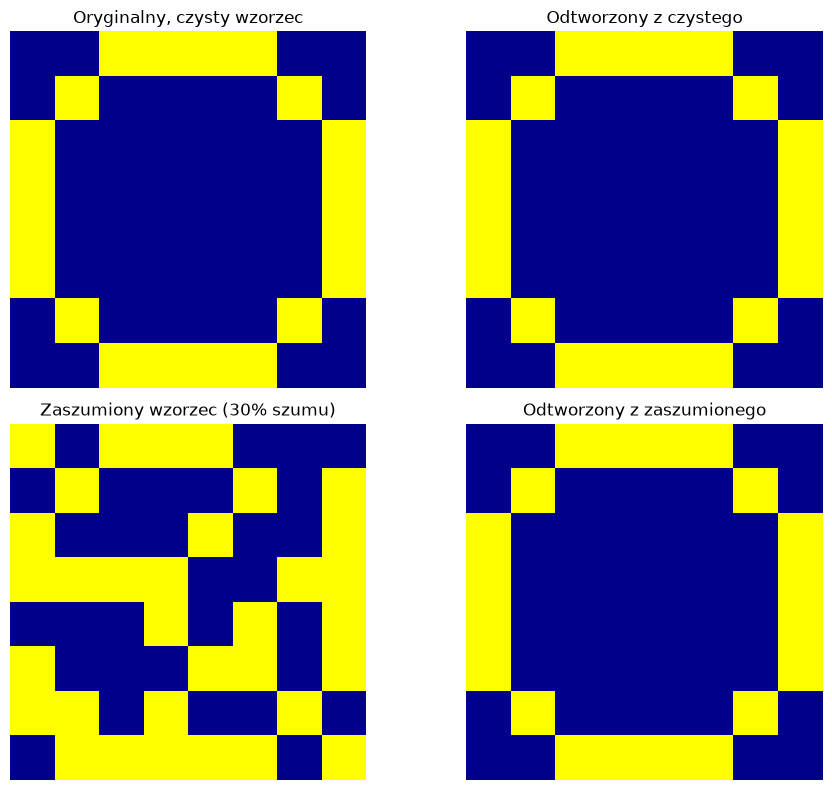

In [10]:
wzorzec_testowy = wzorce[0]
zaszumiony_testowy = wzorce_zaszumione_30[0]
odtworzony = odtworz_obraz(wzorzec_testowy, wagi, 10)
odtworzony_zaszumiony = odtworz_obraz(zaszumiony_testowy, wagi, 10)
fig, osie = plt.subplots(2, 2, figsize=(10, 8))

osie[0, 0].imshow(wzorzec_testowy, cmap=moje_kolory)
osie[0, 0].set_title("Oryginalny, czysty wzorzec")
osie[0, 0].axis('off')

osie[0, 1].imshow(odtworzony, cmap=moje_kolory)
osie[0, 1].set_title("Odtworzony z czystego")
osie[0, 1].axis('off')

osie[1, 0].imshow(zaszumiony_testowy, cmap=moje_kolory)
osie[1, 0].set_title("Zaszumiony wzorzec (30% szumu)")
osie[1, 0].axis('off')

osie[1, 1].imshow(odtworzony_zaszumiony, cmap=moje_kolory)
osie[1, 1].set_title("Odtworzony z zaszumionego")
osie[1, 1].axis('off')

plt.tight_layout()
plt.show()